In [1]:

# %pip install pandas numpy scikit-learn matplotlib seaborn joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.preprocessing import LabelEncoder
import joblib

RANDOM_STATE = 42


In [5]:
# Run this notebook from the project folder, or update DATA_PATH to your dataset location.
DATA_PATH = Path("../data/smart_classroom_energy_dataset.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/smart_classroom_energy_dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Open this notebook from the project folder, "
        "or set DATA_PATH to data/smart_classroom_energy_dataset.csv."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (2400, 5)


,light_level_lux,motion_detected,hour_of_day,scheduled_day,lights_action
0,107,0,14,1,OFF
1,779,1,14,0,OFF
2,662,1,5,0,OFF
3,450,1,19,0,OFF
4,444,0,16,0,OFF


In [6]:
print("Missing values per column:")
display(df.isna().sum())
print("\nTarget distribution:")
display(df["lights_action"].value_counts())
print("\nSummary statistics:")
display(df.describe(include="all"))


Missing values per column:


light_level_lux    0
motion_detected    0
hour_of_day        0
scheduled_day      0
lights_action      0
dtype: int64


Target distribution:


lights_action
OFF    2301
ON       99
Name: count, dtype: int64


Summary statistics:


,light_level_lux,motion_detected,hour_of_day,scheduled_day,lights_action
count,2400.000000,2400.000000,2400.000000,2400.000000,2400
unique,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,OFF
freq,NaN,NaN,NaN,NaN,2301
mean,510.523750,0.482917,11.376250,0.494167,NaN
std,283.504776,0.499812,6.901717,0.500070,NaN
min,20.000000,0.000000,0.000000,0.000000,NaN
25%,265.000000,0.000000,5.000000,0.000000,NaN
50%,509.000000,0.000000,11.000000,0.000000,NaN
75%,756.000000,1.000000,17.000000,1.000000,NaN


In [5]:
required_columns = {
    "light_level_lux", "motion_detected", "hour_of_day",
    "scheduled_day", "lights_action"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

assert df["light_level_lux"].between(0, 2000).all(), "Unexpected light sensor range."
assert df["motion_detected"].isin([0, 1]).all(), "motion_detected must be 0 or 1."
assert df["hour_of_day"].between(0, 23).all(), "hour_of_day must be 0 to 23."
assert df["scheduled_day"].isin([0, 1]).all(), "scheduled_day must be 0 or 1."
assert df["lights_action"].isin(["ON", "OFF"]).all(), "Target must be ON or OFF."
print("Basic data validation passed.")


Basic data validation passed.


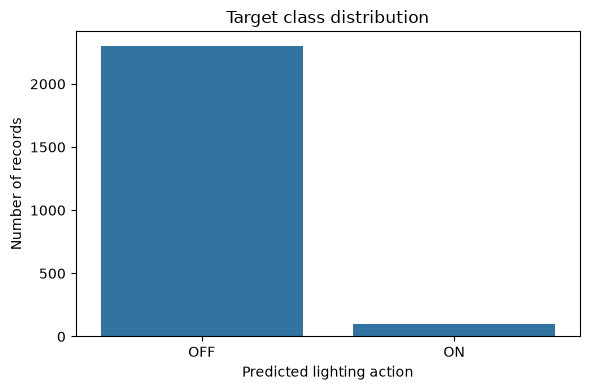

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="lights_action")
plt.title("Target class distribution")
plt.xlabel("Predicted lighting action")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()


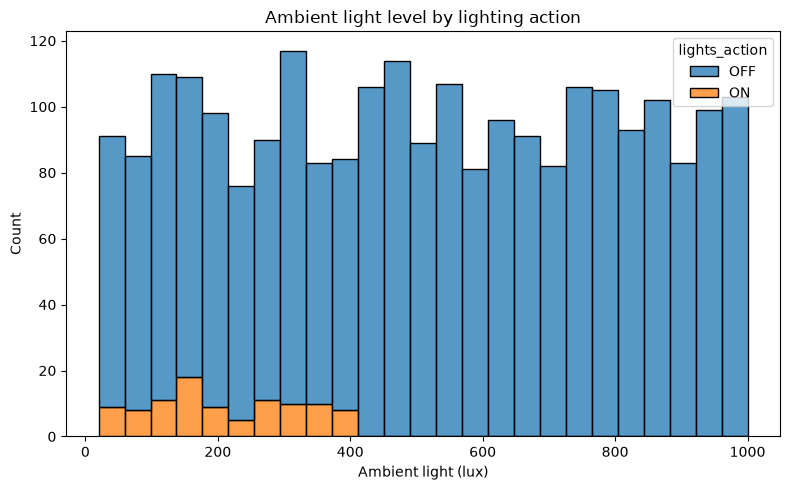

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="light_level_lux", hue="lights_action", bins=25, multiple="stack")
plt.title("Ambient light level by lighting action")
plt.xlabel("Ambient light (lux)")
plt.tight_layout()
plt.show()


In [9]:
FEATURES = ["light_level_lux", "motion_detected", "hour_of_day", "scheduled_day"]
TARGET = "lights_action"

X = df[FEATURES].copy()
y = df[TARGET].copy()

# Stratification preserves the ON/OFF proportion in both subsets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 1920
Testing records: 480


In [10]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=6,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=RANDOM_STATE
)
model.fit(X_train, y_train)
print("Decision Tree training completed.")


Decision Tree training completed.


In [11]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


Test accuracy: 1.0000 (100.00%)

Classification report:
              precision    recall  f1-score   support

         OFF       1.00      1.00      1.00       460
          ON       1.00      1.00      1.00        20

    accuracy                           1.00       480
   macro avg       1.00      1.00      1.00       480
weighted avg       1.00      1.00      1.00       480



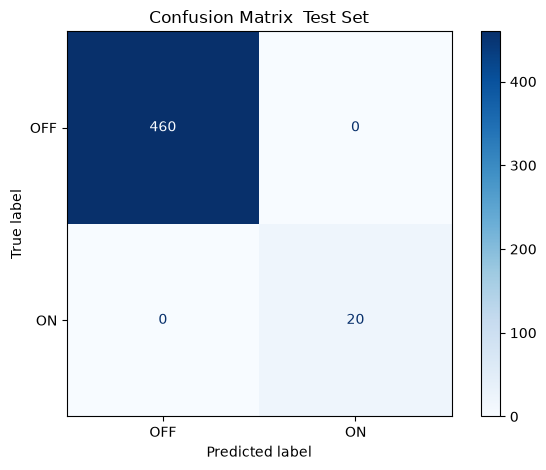

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=["OFF", "ON"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["OFF", "ON"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix  Test Set")
plt.tight_layout()
plt.show()


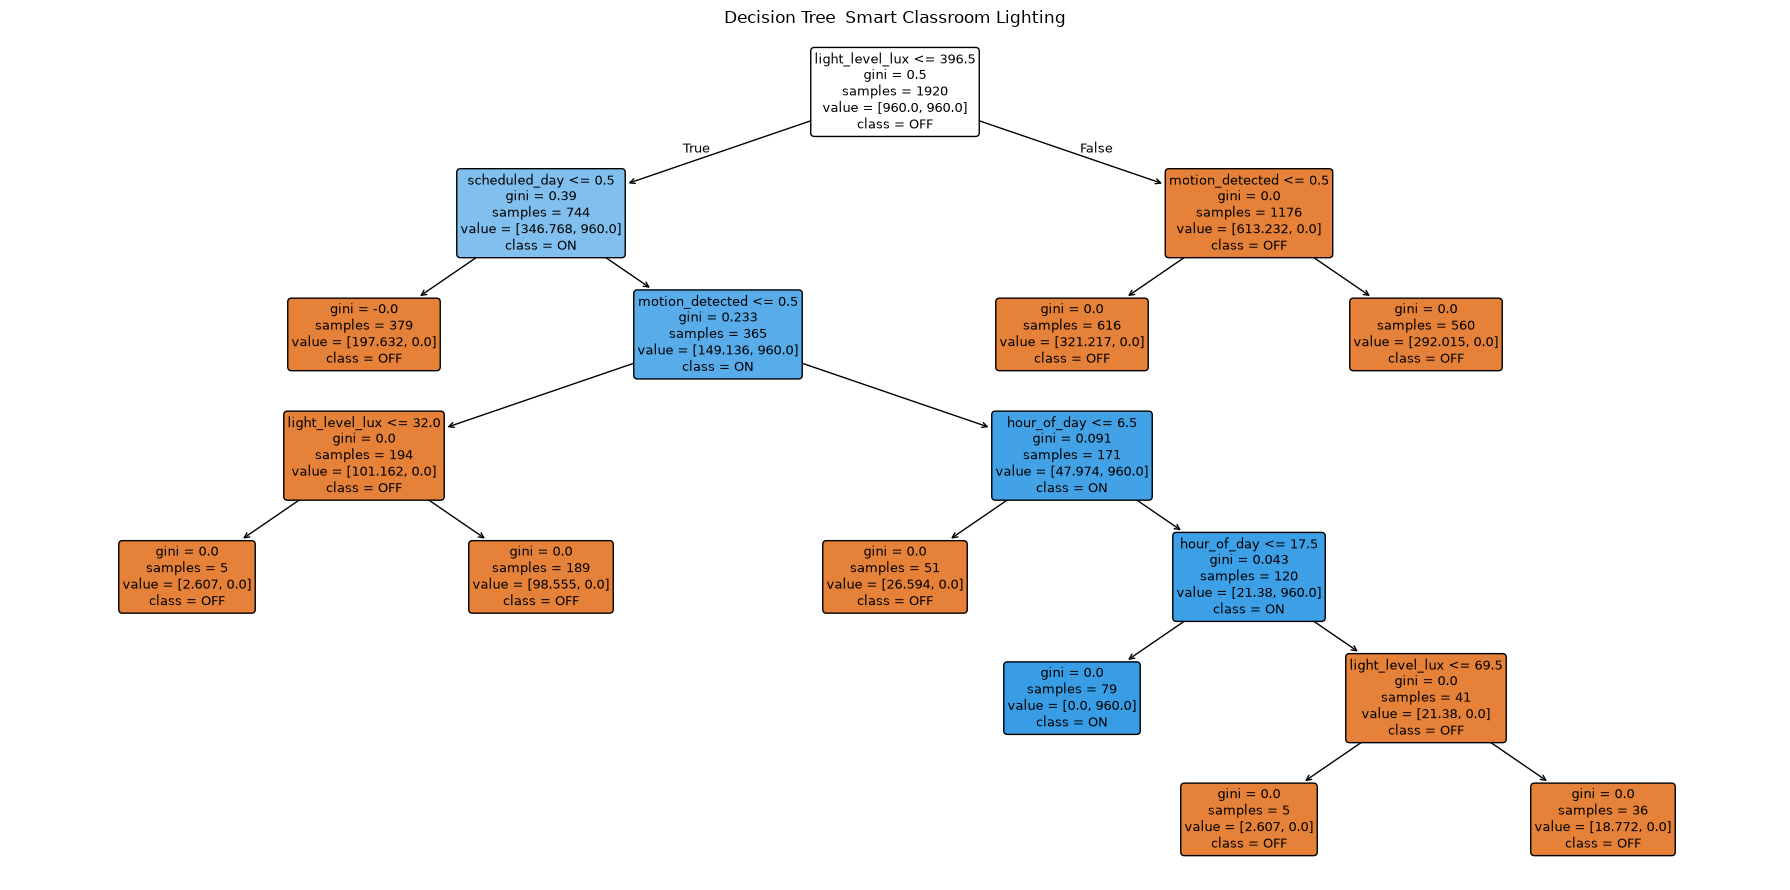

In [15]:
plt.figure(figsize=(18, 9))
plot_tree(
    model,
    feature_names=FEATURES,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree  Smart Classroom Lighting")
plt.tight_layout()
plt.show()


,importance
light_level_lux,0.469274
scheduled_day,0.261803
motion_detected,0.173735
hour_of_day,0.095189


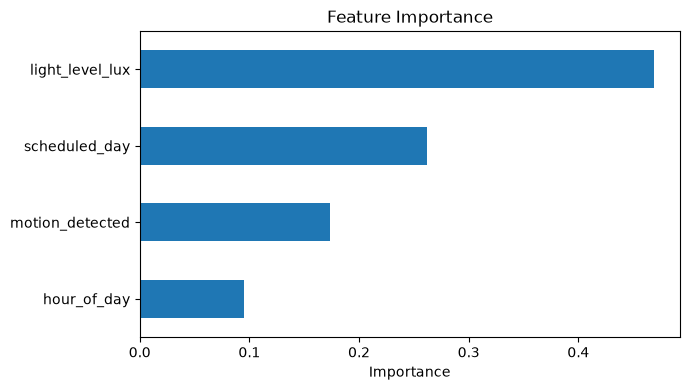

In [16]:
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=False)
display(importance.to_frame("importance"))
importance.sort_values().plot(kind="barh", figsize=(7, 4), title="Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [12]:

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display

# 1. Example training dataset
# Replace this illustrative data with your actual project dataset.
training_data = pd.DataFrame({
    "light_level_lux": [50, 180, 300, 50, 180, 300, 80, 250],
    "motion_detected": [1, 1, 1, 0, 0, 0, 1, 0],
    "hour_of_day": [10, 10, 10, 22, 22, 22, 18, 14],
    "scheduled_day": [1, 1, 1, 1, 1, 1, 0, 1]
})

# Example labels: 1 = ON, 0 = OFF
target = [1, 1, 0, 0, 0, 0, 1, 0]

# 2. Define and train the model
model = RandomForestClassifier(random_state=42)
model.fit(training_data, target)

# 3. Your sample input
sample = pd.DataFrame([{
    "light_level_lux": 180,
    "motion_detected": 1,
    "hour_of_day": 10,
    "scheduled_day": 1
}])

# 4. Make the prediction
prediction = model.predict(sample)[0]

print("Sample input:")
display(sample)

print("Recommended light action:", "ON" if prediction == 1 else "OFF")


Sample input:


,light_level_lux,motion_detected,hour_of_day,scheduled_day
0,180,1,10,1


Recommended light action: ON


In [14]:

from pathlib import Path
import pandas as pd
import joblib
from sklearn.tree import DecisionTreeClassifier
from IPython.display import display

# 1. Define the input features
FEATURES = [
    "light_level_lux",
    "motion_detected",
    "hour_of_day",
    "scheduled_day"
]

# 2. Example synthetic training dataset
# Replace this with your real sensor dataset when available.
training_data = pd.DataFrame({
    "light_level_lux": [50, 180, 300, 50, 180, 300, 80, 250],
    "motion_detected": [1, 1, 1, 0, 0, 0, 1, 0],
    "hour_of_day": [10, 10, 10, 22, 22, 22, 18, 14],
    "scheduled_day": [1, 1, 1, 1, 1, 1, 0, 1]
})

# Example labels: 1 = ON, 0 = OFF
target = [1, 1, 0, 0, 0, 0, 1, 0]

# 3. Create and train the decision tree model
model = DecisionTreeClassifier(random_state=42)
model.fit(training_data[FEATURES], target)

# 4. Predict using your sample input
sample = pd.DataFrame([{
    "light_level_lux": 180,
    "motion_detected": 1,
    "hour_of_day": 10,
    "scheduled_day": 1
}])

prediction = model.predict(sample[FEATURES])[0]

print("Sample input:")
display(sample)

print(
    "Recommended light action:",
    "ON" if prediction == 1 else "OFF"
)

# 5. Set the output directory
OUTPUT_DIR = Path("../models")

if not OUTPUT_DIR.exists():
    OUTPUT_DIR = Path("models")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 6. Package the model and its metadata
artifact = {
    "model": model,
    "features": FEATURES,
    "classes": list(model.classes_),
    "dataset_note": (
        "Synthetic demonstration dataset; "
        "validate with real sensor readings."
    )
}

# 7. Save the model artifact
model_path = OUTPUT_DIR / "smart_classroom_decision_tree.joblib"

joblib.dump(artifact, model_path)

print("Saved model to:", model_path.resolve())



Sample input:


,light_level_lux,motion_detected,hour_of_day,scheduled_day
0,180,1,10,1


Recommended light action: ON
Saved model to: C:\Users\kenny\Desktop\WORKS OF ETT\ML learning\Smart_Classroom_Energy_System\models\smart_classroom_decision_tree.joblib


In [15]:

from pathlib import Path
import joblib
import pandas as pd
from IPython.display import display

# 1. Locate the saved model
model_path = OUTPUT_DIR / "smart_classroom_decision_tree.joblib"

# 2. Load the saved artifact
artifact = joblib.load(model_path)

# 3. Recover the model and feature names
loaded_model = artifact["model"]
FEATURES = artifact["features"]

print("Model loaded successfully!")
print("Features:", FEATURES)
print("Classes:", artifact["classes"])

# 4. Prepare a new sample
new_sample = pd.DataFrame([{
    "light_level_lux": 180,
    "motion_detected": 1,
    "hour_of_day": 10,
    "scheduled_day": 1
}])

# 5. Make a prediction using the loaded model
prediction = loaded_model.predict(new_sample[FEATURES])[0]

print("\nTest input:")
display(new_sample)

print(
    "Recommended light action:",
    "ON" if prediction == 1 else "OFF"
)


Model loaded successfully!
Features: ['light_level_lux', 'motion_detected', 'hour_of_day', 'scheduled_day']
Classes: [np.int64(0), np.int64(1)]

Test input:


,light_level_lux,motion_detected,hour_of_day,scheduled_day
0,180,1,10,1


Recommended light action: ON
